# Assignment Problems: Day 8
The following problems require access to the file named ‘Dataset_Day8.csv’, provided with this assignment. 

This is the same assignment data as Day 7.

The datasets include data from 768 women with several medical predictor variables and one target variable(‘Outcome’). The classification goal is to predict whether or not the patients in the dataset have diabetes or not.

For columns: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction

If the column value is 0, then they should be considered as missing data.

In [1]:
import numpy as np
import pandas as pd
from math import log, sqrt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

* Firstly, replace all Missing values with relevant figures.
* Then remove all existing outliers and get the final data for classification.

In [2]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame(columns = ["Pregnancies","Glucose","BloodPressure","BMI","Age"])
temp = data.drop('Outcome',axis=1)
for col in ["Pregnancies","Glucose","BloodPressure","BMI","Age"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    outlier[col] = temp[col][(temp[col]<=LowerBound)|(temp[col]>=UpperBound)]

OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))

Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0

no. of Outlier 4 
% of Outlier =  0.5208333333333333


C:\Users\nikhi\AppData\Local\Temp\ipykernel_5216\3315839205.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()


* Split the data into 70% training and 30% testing data. Then, use a k-Nearest Neighbor algorithm with target variable as ‘Outcome’.
* Print the default model performance metrics: Accuracy, Precision, Recall, F1Score
* Plot a Precision & Recall vs k(no. of neighbours) curve (both Prec and Rec on the same graph). Find the k for which F1-score is the highest. Use any one Distance Metric for this problem.

In [3]:
OutlierFreeData.corr()

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.119049,0.217756,0.009581,-0.031852,0.546169,0.205240
Glucose,0.119049,1.000000,0.222476,0.230177,0.138453,0.265965,0.491863
BloodPressure,0.217756,0.222476,1.000000,0.281800,-0.003360,0.325915,0.167769
BMI,0.009581,0.230177,0.281800,1.000000,0.153506,0.022265,0.309453
DiabetesPedigreeFunction,-0.031852,0.138453,-0.003360,0.153506,1.000000,0.033822,0.176598
Age,0.546169,0.265965,0.325915,0.022265,0.033822,1.000000,0.233776
Outcome,0.205240,0.491863,0.167769,0.309453,0.176598,0.233776,1.000000


Model Performance metrics are as below :-

Accuracy is 0.8304347826086956
Precision is 0.8333333333333334
Recall is 0.6329113924050633
F1-Score is 0.7194244604316549
[[141  10]
 [ 29  50]]


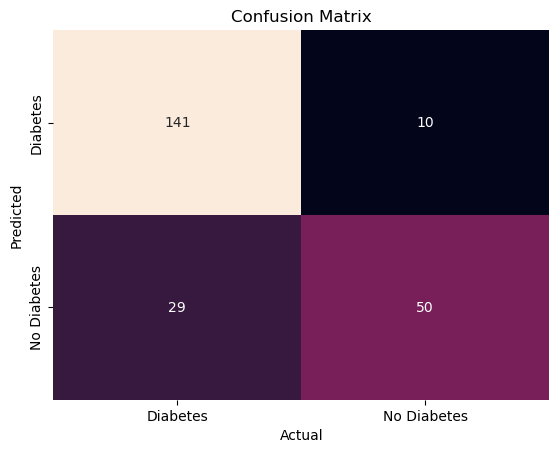

In [4]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30, random_state=44)
k = int(sqrt(len(X_train)))
if k/2 == 0:
    k += 1
model = KNeighborsClassifier(n_neighbors = k, metric = 'euclidean')
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is "+str(accuracy_score(y_test,y_pred)))
print("Precision is "+str(precision_score(y_test,y_pred)))
print("Recall is "+str(recall_score(y_test,y_pred)))
print("F1-Score is "+str(f1_score(y_test,y_pred)))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()

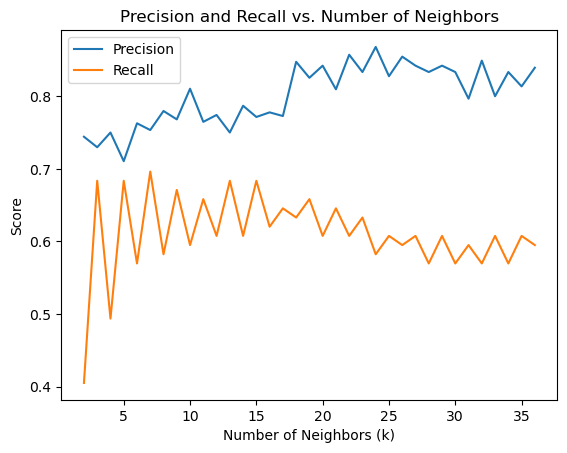

,k,accuracy,f1_score,precision,recall
17,19,0.834783,0.732394,0.825397,0.658228


In [5]:
df = pd.DataFrame(columns = ['k','accuracy','f1_score','precision','recall'])
for k in range(2,int(sqrt(len(X_train))+sqrt(len(X_test))-1)):
    model = KNeighborsClassifier(n_neighbors = k, metric = 'euclidean')
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    df = pd.concat([pd.DataFrame([[k,accuracy_score(y_test,y_pred),f1_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)

# Plotting precision and recall scores against k values
plt.plot(df["k"], df["precision"], label='Precision')
plt.plot(df["k"], df["recall"], label='Recall')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Number of Neighbors')
plt.legend()
plt.show()

df[df['f1_score'] == max(df['f1_score'])]

In [6]:
df = pd.DataFrame(columns = ['k','metric','accuracy','f1_score','precision','recall'])
for metric in ['euclidean','manhattan','minkowski','cosine','hamming']:
    for k in range(2,int(sqrt(len(X_train))+sqrt(len(X_test))-1)):
        model = KNeighborsClassifier(n_neighbors = k, metric = metric)
        model.fit(X_train,y_train)
        y_pred = model.predict(X_test)
        df = pd.concat([pd.DataFrame([[k,metric,accuracy_score(y_test,y_pred),f1_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)
df

,k,metric,accuracy,f1_score,precision,recall
0,36,hamming,0.660870,0.025000,1.000000,0.012658
1,35,hamming,0.660870,0.025000,1.000000,0.012658
2,34,hamming,0.660870,0.025000,1.000000,0.012658
3,33,hamming,0.660870,0.025000,1.000000,0.012658
4,32,hamming,0.660870,0.025000,1.000000,0.012658
...,...,...,...,...,...,...
170,6,euclidean,0.791304,0.652174,0.762712,0.569620
171,5,euclidean,0.795652,0.696774,0.710526,0.683544
172,4,euclidean,0.769565,0.595420,0.750000,0.493671
173,3,euclidean,0.804348,0.705882,0.729730,0.683544


* Find the best distance metric, no. of neighbors combination for the kNN algorithm

In [7]:
df[df['f1_score'] == max(df['f1_score'])]

,k,metric,accuracy,f1_score,precision,recall
106,35,manhattan,0.847826,0.744526,0.87931,0.64557
108,33,manhattan,0.847826,0.744526,0.87931,0.64557
110,31,manhattan,0.847826,0.744526,0.87931,0.64557


Name - Nikhil Khatri

SIC  - 21BCSA92